In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../dataset/AquaSense_Cleaned_Data.csv")

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (46032, 13)


,Date,Time,Consumption,Temperature,Rain,Sun,Hour,Timestamp,Day,Month,Year,DayOfWeek,Weekday
0,2016-01-01,00:00-01:00,1480,0.6,0.0,0,0,2016-01-01 00:00:00,1,1,2016,4,Friday
1,2016-01-01,01:00-02:00,1362,0.6,0.0,0,1,2016-01-01 01:00:00,1,1,2016,4,Friday
2,2016-01-01,02:00-03:00,1296,0.5,0.0,0,2,2016-01-01 02:00:00,1,1,2016,4,Friday
3,2016-01-01,03:00-04:00,1096,0.0,0.0,0,3,2016-01-01 03:00:00,1,1,2016,4,Friday
4,2016-01-01,04:00-05:00,810,0.3,0.0,0,4,2016-01-01 04:00:00,1,1,2016,4,Friday


In [3]:
print("Water Consumption Statistics")

print(df["Consumption"].describe())

Water Consumption Statistics
count    46032.000000
mean      2314.342544
std       1032.138095
min          1.000000
25%       1461.000000
50%       2550.000000
75%       3082.000000
max       6514.000000
Name: Consumption, dtype: float64


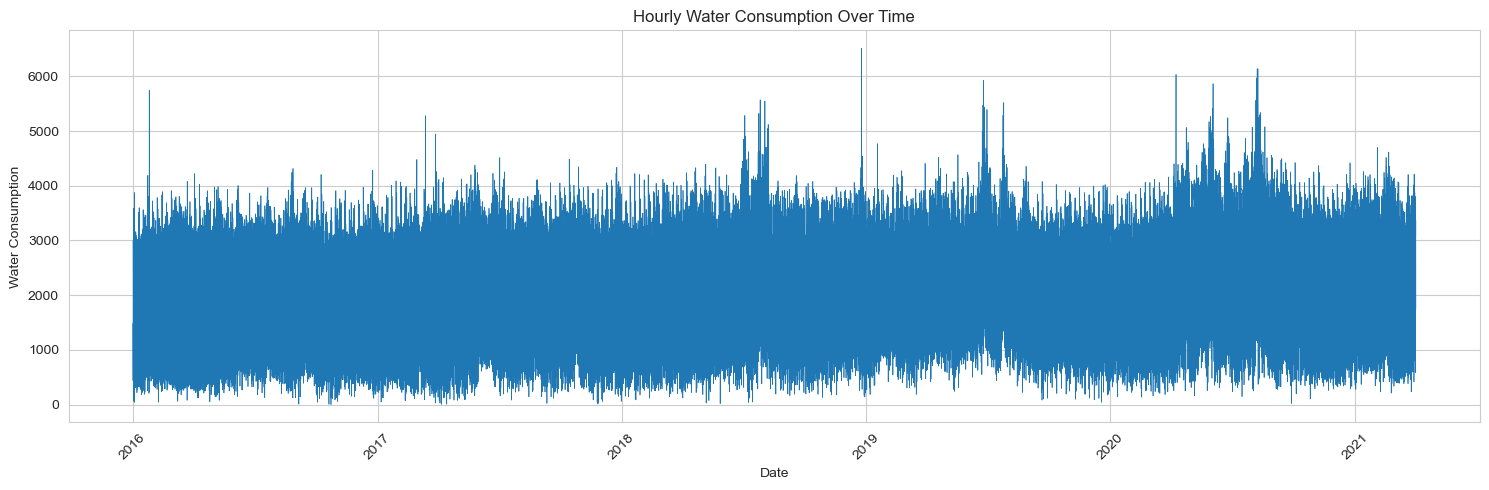

In [4]:
plt.figure(figsize=(15, 5))

plt.plot(
    df["Timestamp"],
    df["Consumption"],
    linewidth=0.5
)

plt.title("Hourly Water Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Water Consumption")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

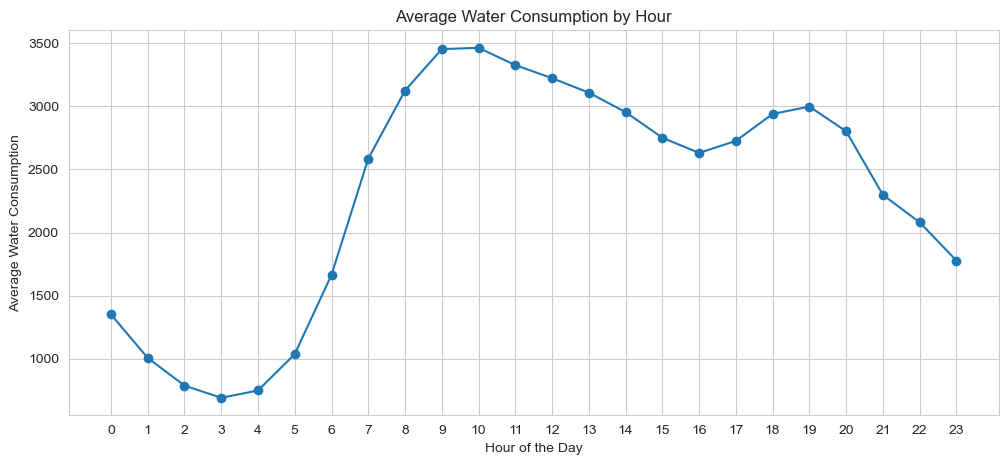

In [5]:
# Calculate average water consumption for each hour
hourly_consumption = df.groupby("Hour")["Consumption"].mean()

# Plot the graph
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o"
)

plt.title("Average Water Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Water Consumption")
plt.xticks(range(24))
plt.grid(True)

plt.show()

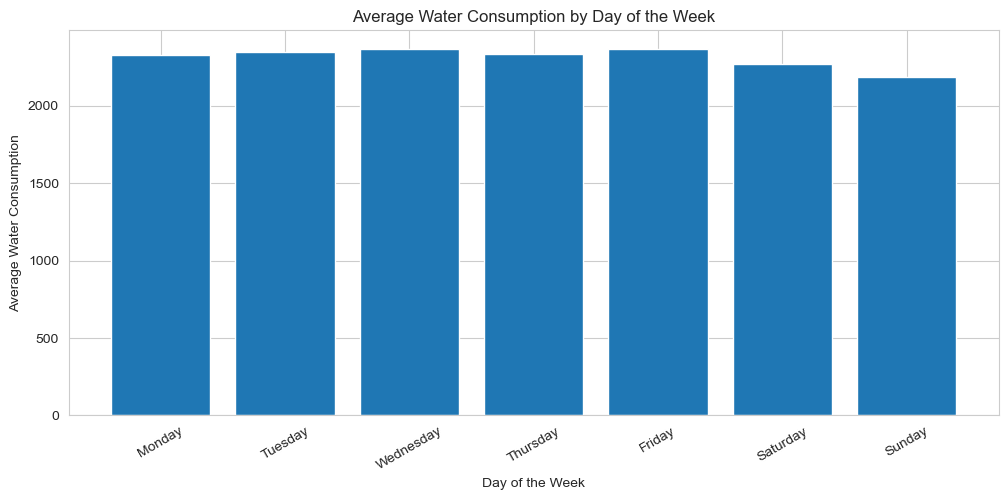

In [6]:
# Calculate average consumption for each weekday
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_consumption = (
    df.groupby("Weekday")["Consumption"]
    .mean()
    .reindex(weekday_order)
)

# Plot the graph
plt.figure(figsize=(12, 5))

plt.bar(daily_consumption.index, daily_consumption.values)

plt.title("Average Water Consumption by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Water Consumption")
plt.xticks(rotation=30)

plt.show()

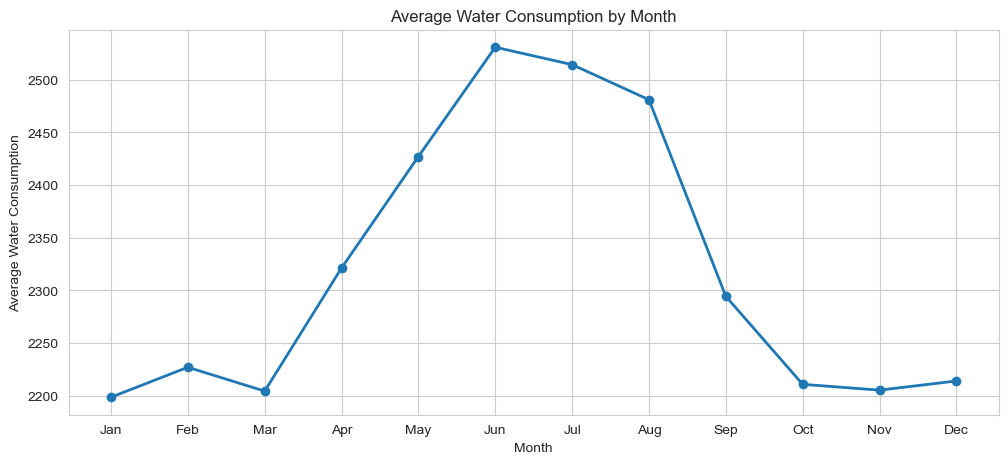

In [7]:
# Calculate average consumption for each month
monthly_consumption = df.groupby("Month")["Consumption"].mean()

# Plot the graph
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_consumption.index,
    monthly_consumption.values,
    marker="o",
    linewidth=2
)

plt.title("Average Water Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Water Consumption")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(True)
plt.show()

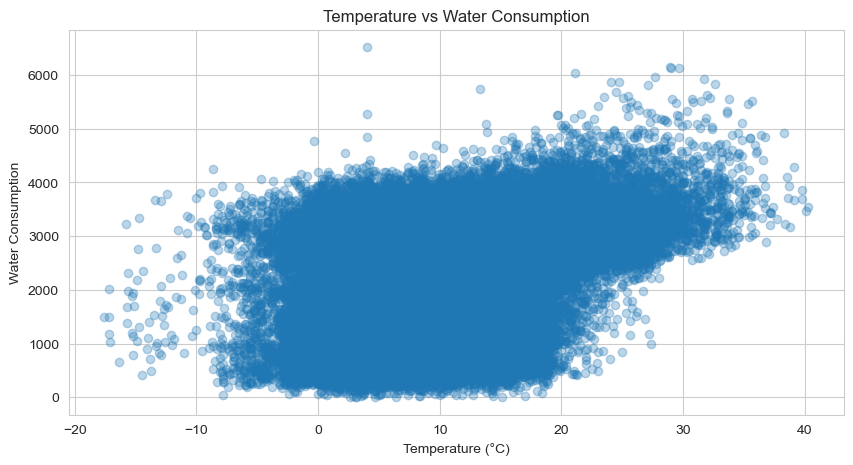

In [8]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["Temperature"],
    df["Consumption"],
    alpha=0.3
)

plt.title("Temperature vs Water Consumption")
plt.xlabel("Temperature (°C)")
plt.ylabel("Water Consumption")

plt.grid(True)
plt.show()

In [9]:
correlation = df["Temperature"].corr(df["Consumption"])

print("Temperature and Consumption Correlation:", correlation)

Temperature and Consumption Correlation: 0.33472475224899656


In [10]:
# Calculate correlations between important variables
correlation_matrix = df[
    ["Consumption", "Temperature", "Rain", "Sun"]
].corr()

print(correlation_matrix)

             Consumption  Temperature      Rain       Sun
Consumption     1.000000     0.334725 -0.000056  0.499151
Temperature     0.334725     1.000000 -0.014456  0.498822
Rain           -0.000056    -0.014456  1.000000 -0.043901
Sun             0.499151     0.498822 -0.043901  1.000000


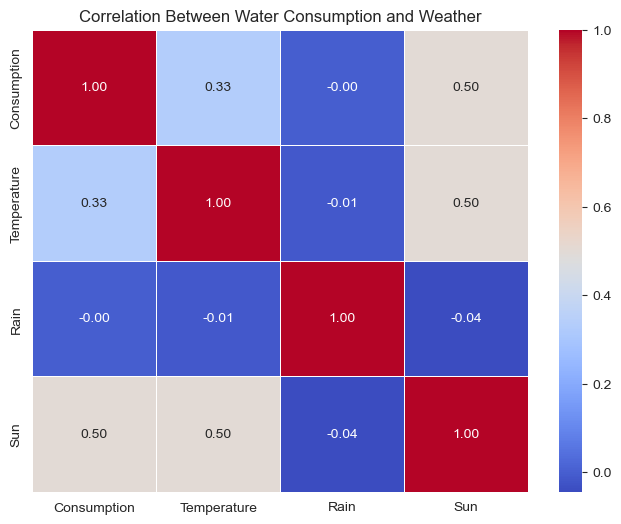

In [11]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Water Consumption and Weather")
plt.show()

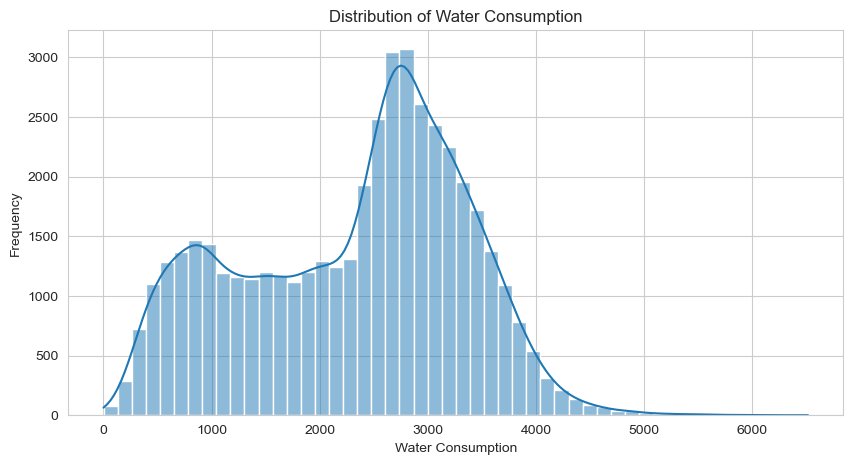

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Consumption"],
    bins=50,
    kde=True
)

plt.title("Distribution of Water Consumption")
plt.xlabel("Water Consumption")
plt.ylabel("Frequency")

plt.show()

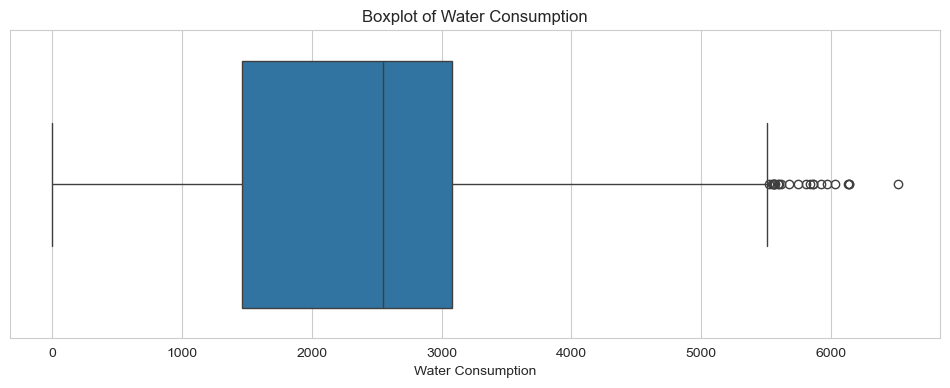

In [13]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=df["Consumption"])

plt.title("Boxplot of Water Consumption")
plt.xlabel("Water Consumption")

plt.show()


In [14]:
Q1 = df["Consumption"].quantile(0.25)
Q3 = df["Consumption"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Consumption"] < lower_limit) |
    (df["Consumption"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Total Outliers:", len(outliers))
print("Percentage of Outliers:", round(
    len(outliers) / len(df) * 100, 2
), "%")

Q1: 1461.0
Q3: 3082.0
IQR: 1621.0
Lower Limit: -970.5
Upper Limit: 5513.5
Total Outliers: 22
Percentage of Outliers: 0.05 %


In [15]:
# Create a separate dataset for machine learning
model_df = df.copy()

# Sort records chronologically
model_df = model_df.sort_values("Timestamp")

# Reset index
model_df = model_df.reset_index(drop=True)

print("Dataset shape:", model_df.shape)

display(model_df.head())

Dataset shape: (46032, 13)


,Date,Time,Consumption,Temperature,Rain,Sun,Hour,Timestamp,Day,Month,Year,DayOfWeek,Weekday
0,2016-01-01,00:00-01:00,1480,0.6,0.0,0,0,2016-01-01 00:00:00,1,1,2016,4,Friday
1,2016-01-01,01:00-02:00,1362,0.6,0.0,0,1,2016-01-01 01:00:00,1,1,2016,4,Friday
2,2016-01-01,02:00-03:00,1296,0.5,0.0,0,2,2016-01-01 02:00:00,1,1,2016,4,Friday
3,2016-01-01,03:00-04:00,1096,0.0,0.0,0,3,2016-01-01 03:00:00,1,1,2016,4,Friday
4,2016-01-01,04:00-05:00,810,0.3,0.0,0,4,2016-01-01 04:00:00,1,1,2016,4,Friday


In [16]:
# Hour-based cyclical features
model_df["Hour_sin"] = np.sin(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Hour_cos"] = np.cos(
    2 * np.pi * model_df["Hour"] / 24
)

# Month-based cyclical features
model_df["Month_sin"] = np.sin(
    2 * np.pi * model_df["Month"] / 12
)

model_df["Month_cos"] = np.cos(
    2 * np.pi * model_df["Month"] / 12
)

print("New cyclical features created!")

display(
    model_df[
        ["Hour", "Hour_sin", "Hour_cos",
         "Month", "Month_sin", "Month_cos"]
    ].head(10)
)

New cyclical features created!


,Hour,Hour_sin,Hour_cos,Month,Month_sin,Month_cos
0,0,0.000000,1.000000e+00,1,0.5,0.866025
1,1,0.258819,9.659258e-01,1,0.5,0.866025
2,2,0.500000,8.660254e-01,1,0.5,0.866025
3,3,0.707107,7.071068e-01,1,0.5,0.866025
4,4,0.866025,5.000000e-01,1,0.5,0.866025
5,5,0.965926,2.588190e-01,1,0.5,0.866025
6,6,1.000000,6.123234e-17,1,0.5,0.866025
7,7,0.965926,-2.588190e-01,1,0.5,0.866025
8,8,0.866025,-5.000000e-01,1,0.5,0.866025
9,9,0.707107,-7.071068e-01,1,0.5,0.866025


In [17]:
# Create previous consumption features

model_df["Lag_1"] = model_df["Consumption"].shift(1)

model_df["Lag_24"] = model_df["Consumption"].shift(24)

model_df["Lag_168"] = model_df["Consumption"].shift(168)

print("Lag features created successfully!")

display(
    model_df[
        ["Timestamp", "Consumption",
         "Lag_1", "Lag_24", "Lag_168"]
    ].head(175)
)

Lag features created successfully!


,Timestamp,Consumption,Lag_1,Lag_24,Lag_168
0,2016-01-01 00:00:00,1480,NaN,NaN,NaN
1,2016-01-01 01:00:00,1362,1480.0,NaN,NaN
2,2016-01-01 02:00:00,1296,1362.0,NaN,NaN
3,2016-01-01 03:00:00,1096,1296.0,NaN,NaN
4,2016-01-01 04:00:00,810,1096.0,NaN,NaN
...,...,...,...,...,...
170,2016-01-08 02:00:00,358,605.0,384.0,1296.0
171,2016-01-08 03:00:00,277,358.0,217.0,1096.0
172,2016-01-08 04:00:00,336,277.0,287.0,810.0
173,2016-01-08 05:00:00,783,336.0,920.0,474.0


In [18]:
# Calculate rolling averages using previous observations only

model_df["Rolling_Mean_24"] = (
    model_df["Consumption"]
    .shift(1)
    .rolling(window=24)
    .mean()
)

model_df["Rolling_Mean_168"] = (
    model_df["Consumption"]
    .shift(1)
    .rolling(window=168)
    .mean()
)

print("Rolling features created successfully!")

display(
    model_df[
        ["Timestamp", "Consumption",
         "Rolling_Mean_24", "Rolling_Mean_168"]
    ].head(175)
)

Rolling features created successfully!


,Timestamp,Consumption,Rolling_Mean_24,Rolling_Mean_168
0,2016-01-01 00:00:00,1480,NaN,NaN
1,2016-01-01 01:00:00,1362,NaN,NaN
2,2016-01-01 02:00:00,1296,NaN,NaN
3,2016-01-01 03:00:00,1096,NaN,NaN
4,2016-01-01 04:00:00,810,NaN,NaN
...,...,...,...,...
170,2016-01-08 02:00:00,358,1999.375000,1948.821429
171,2016-01-08 03:00:00,277,1998.291667,1943.238095
172,2016-01-08 04:00:00,336,2000.791667,1938.363095
173,2016-01-08 05:00:00,783,2002.833333,1935.541667


In [19]:
print("Missing values in each column:")
print(model_df.isnull().sum())

print("\nTotal missing values:",
      model_df.isnull().sum().sum())

Missing values in each column:
Date                  0
Time                  0
Consumption           0
Temperature           0
Rain                  0
Sun                   0
Hour                  0
Timestamp             0
Day                   0
Month                 0
Year                  0
DayOfWeek             0
Weekday               0
Hour_sin              0
Hour_cos              0
Month_sin             0
Month_cos             0
Lag_1                 1
Lag_24               24
Lag_168             168
Rolling_Mean_24      24
Rolling_Mean_168    168
dtype: int64

Total missing values: 385


In [20]:
# Remove rows where historical features are unavailable
model_df = model_df.dropna().reset_index(drop=True)

print("Dataset shape after removing missing rows:",
      model_df.shape)

print("\nRemaining missing values:")
print(model_df.isnull().sum().sum())

Dataset shape after removing missing rows: (45864, 22)

Remaining missing values:
0


In [21]:
model_df.to_csv(
    "../dataset/AquaSense_Feature_Engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")

Feature-engineered dataset saved successfully!
